### Import libraries and define project paths

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 100)

# Assumes this notebook is stored in <project_root>/notebooks/
PROJECT_ROOT = Path.cwd().parent
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports"
SHAP_DIR = REPORT_DIR / "shap"
SURVIVAL_DIR = REPORT_DIR / "survival"
OUTPUT_DIR = REPORT_DIR / "retention"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT.resolve())
print("Model directory:", MODEL_DIR.resolve())
print("Output directory:", OUTPUT_DIR.resolve())

Project root: C:\CHURNIQ
Model directory: C:\CHURNIQ\MODELS
Output directory: C:\CHURNIQ\REPORTS\retention


### Load the existing Telco customer data

In [2]:

from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nCSV files in the current directory:")
for file in Path.cwd().glob("*.csv"):
    print(file.resolve())


Current working directory:
C:\CHURNIQ\NOTEBOOKS

CSV files in the current directory:


In [5]:

from pathlib import Path
import pandas as pd

# Correct path to the Telco Customer Churn dataset
DATA_CANDIDATES = [
    Path(r"C:\CHURNIQ\DATA\WA_Fn-UseC_-Telco-Customer-Churn.csv"),
    Path(r"C:\CHURNIQ\SQL\psql telco_customers_data.csv"),
]

# Find the first available dataset
data_path = next(
    (p for p in DATA_CANDIDATES if p.is_file()),
    None
)

if data_path is None:
    raise FileNotFoundError(
        "Telco dataset not found. Check the CSV path."
    )

# Load dataset
df = pd.read_csv(data_path)

# Clean column names
df.columns = df.columns.astype(str).str.strip()

print("Dataset loaded successfully!")
print("File used:", data_path)
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


Dataset loaded successfully!
File used: C:\CHURNIQ\DATA\WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset shape: (7043, 26)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,NaN,NaN,NaN,NaN,NaN
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No,NaN,NaN,NaN,NaN,NaN
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,NaN,NaN,NaN,NaN,NaN
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,NaN,NaN,NaN,NaN,NaN
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,NaN,NaN,create table telco_customers(,NaN,NaN


### Standardize key fields and validate the target

In [6]:
def get_col(frame, name):
    matches = [c for c in frame.columns if str(c).strip().lower() == name.strip().lower()]
    return matches[0] if matches else None

customer_id_col = get_col(df, "customerid") or get_col(df, "customer_id")
churn_col = get_col(df, "churn") or get_col(df, "churn_target")
tenure_col = get_col(df, "tenure_months") or get_col(df, "tenure")
monthly_col = get_col(df, "monthlycharges") or get_col(df, "monthly_charges")
contract_col = get_col(df, "contract") or get_col(df, "contract_type")

if customer_id_col is None:
    df["customer_id"] = [f"customer_{i+1}" for i in range(len(df))]
    customer_id_col = "customer_id"

if tenure_col is not None:
    df[tenure_col] = pd.to_numeric(df[tenure_col], errors="coerce")
if monthly_col is not None:
    df[monthly_col] = pd.to_numeric(df[monthly_col], errors="coerce")

if churn_col is not None:
    churn_text = df[churn_col].astype("string").str.strip().str.lower()
    churn_map = {"yes": 1, "no": 0, "1": 1, "0": 0, "true": 1, "false": 0}
    df["actual_churn"] = churn_text.map(churn_map)
    print("Observed churn labels:", df["actual_churn"].value_counts(dropna=False).to_dict())
else:
    df["actual_churn"] = np.nan
    warnings.warn("No churn target found. The notebook can score customers, but cannot summarize observed churn.")

print("Customer ID field:", customer_id_col)
print("Tenure field:", tenure_col)
print("Monthly charge field:", monthly_col)
print("Contract field:", contract_col)

Observed churn labels: {0: 5174, 1: 1869}
Customer ID field: customerID
Tenure field: tenure
Monthly charge field: MonthlyCharges
Contract field: Contract


### Load the trained LightGBM model from Notebook 04

In [7]:
MODEL_PATH = MODEL_DIR / "churniq_lightgbm_pipeline.joblib"

if not MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"Trained model not found at {MODEL_PATH.resolve()}. "
        "Run Notebook 04 and save the fitted LightGBM pipeline before running Notebook 07."
    )

churn_model = joblib.load(MODEL_PATH)

# Identify exact feature columns used by the saved model.
expected_features = getattr(churn_model, "feature_names_in_", None)
if expected_features is not None:
    expected_features = list(expected_features)
else:Prepare the scoring matrix without changing the trained feature definitions
    x_train_path = MODEL_DIR / "X_train.csv"
    if not x_train_path.is_file():
        raise FileNotFoundError(
            "The pipeline does not expose feature_names_in_ and models/X_train.csv is missing. "
            "Run Notebook 03/04 and save X_train.csv."
        )
    expected_features = pd.read_csv(x_train_path, nrows=0).columns.tolist()

print("Model:", MODEL_PATH.name)
print("Number of expected features:", len(expected_features))
print("First features:", expected_features[:15])Prepare the scoring matrix without changing the trained feature definitions

Model: churniq_lightgbm_pipeline.joblib
Number of expected features: 8
First features: ['tenure_months', 'is_new_customer', 'is_long_term_customer', 'avg_historical_monthly_charge', 'charge_difference', 'charge_difference_pct', 'is_month_to_month', 'is_long_contract']


### Prepare the scoring matrix without changing the trained feature definitions

In [9]:

import numpy as np
import pandas as pd

# Normalize column names for reliable matching
column_lookup = {
    str(col).strip().lower(): col
    for col in df.columns
}

# Verify required original dataset columns
required_columns = [
    "tenure", "totalcharges", "monthlycharges", "contract"
]

missing_columns = [
    col for col in required_columns
    if col not in column_lookup
]

if missing_columns:
    raise ValueError(
        f"Original dataset is missing columns: {missing_columns}"
    )

# Read original columns and convert numeric values
tenure = pd.to_numeric(
    df[column_lookup["tenure"]], errors="coerce"
)

total_charges = pd.to_numeric(
    df[column_lookup["totalcharges"]], errors="coerce"
)

monthly_charges = pd.to_numeric(
    df[column_lookup["monthlycharges"]], errors="coerce"
)

contract = (
    df[column_lookup["contract"]]
    .astype("string")
    .str.strip()
)

# 1. Standardized tenure
df["tenure_months"] = tenure

# 2. New customer indicator
df["is_new_customer"] = (
    df["tenure_months"] == 0
).astype(int)

# 3. Long-term customer indicator
# IMPORTANT: Use the same threshold as Notebook 03.
df["is_long_term_customer"] = (
    df["tenure_months"] >= 24
).astype(int)

# 4. Average historical monthly charge
valid_tenure = df["tenure_months"].where(
    df["tenure_months"] > 0
)

df["avg_historical_monthly_charge"] = (
    total_charges / valid_tenure
)

# 5. Difference between current and historical average charges
df["charge_difference"] = (
    monthly_charges
    - df["avg_historical_monthly_charge"]
)

# 6. Percentage charge difference
valid_average = df[
    "avg_historical_monthly_charge"
].where(
    df["avg_historical_monthly_charge"] != 0
)

df["charge_difference_pct"] = (
    df["charge_difference"] / valid_average
) * 100

# 7. Contract indicators
df["is_month_to_month"] = (
    contract == "Month-to-month"
).astype(int)

df["is_long_contract"] = contract.isin(
    ["One year", "Two year"]
).astype(int)

print("Feature engineering completed.")
print("\nNew features:")
print([
    "tenure_months",
    "is_new_customer",
    "is_long_term_customer",
    "avg_historical_monthly_charge",
    "charge_difference",
    "charge_difference_pct",
    "is_month_to_month",
    "is_long_contract"
])

display(df.head())


Feature engineering completed.

New features:
['tenure_months', 'is_new_customer', 'is_long_term_customer', 'avg_historical_monthly_charge', 'charge_difference', 'charge_difference_pct', 'is_month_to_month', 'is_long_contract']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,actual_churn,tenure_months,is_new_customer,is_long_term_customer,avg_historical_monthly_charge,charge_difference,charge_difference_pct,is_month_to_month,is_long_contract
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,NaN,NaN,NaN,NaN,NaN,0,1,0,0,29.850000,0.000000,0.000000,1,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No,NaN,NaN,NaN,NaN,NaN,0,34,0,1,55.573529,1.376471,2.476846,0,1
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,NaN,NaN,NaN,NaN,NaN,1,2,0,0,54.075000,-0.225000,-0.416089,1,0
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,NaN,NaN,NaN,NaN,NaN,0,45,0,1,40.905556,1.394444,3.408937,0,1
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,NaN,NaN,create table telco_customers(,NaN,NaN,1,2,0,0,75.825000,-5.125000,-6.758985,1,0


In [11]:
# The saved model's expected columns and order are the source of truth.
# This cell does not fit a new encoder or train a new model.
X_score = pd.DataFrame(index=df.index)
missing_features = []

for feature in expected_features:
    matched = get_col(df, feature)
    if matched is None:
        missing_features.append(feature)
    else:
        X_score[feature] = df[matched]

if missing_features:
    raise ValueError(
        "Scoring data is missing model features: "
        + ", ".join(missing_features)
        + ". Use the same cleaned/engineered feature table and column names as Notebook 04."
    )

X_score = X_score[expected_features]
print("Scoring matrix shape:", X_score.shape)
print("Missing feature columns:", missing_features)

Scoring matrix shape: (7043, 8)
Missing feature columns: []


### Predict customer churn probability

In [13]:

import os
import warnings

os.environ["LOKY_MAX_CPU_COUNT"] = "4"

warnings.filterwarnings(
    "ignore",
    message="Could not find the number of physical cores.*",
    category=UserWarning
)


In [14]:
probabilities = churn_model.predict_proba(X_score)[:, 1]

scores = pd.DataFrame({
    "customer_id": df[customer_id_col].astype(str).to_numpy(),
    "predicted_churn_probability": probabilities,
})

if "actual_churn" in df.columns:
    scores["actual_churn"] = df["actual_churn"].to_numpy()

# Attach interpretable customer context for retention planning.
for source_col, output_col in [
    (tenure_col, "tenure_months"),
    (monthly_col, "monthly_charges"),
    (contract_col, "contract_type"),
]:
    if source_col is not None:
        scores[output_col] = df[source_col].to_numpy()

if get_col(df, "internetservice") is not None:
    scores["internet_service"] = df[get_col(df, "internetservice")].to_numpy()

display(scores.head())
print("Customers scored:", len(scores))

,customer_id,predicted_churn_probability,actual_churn,tenure_months,monthly_charges,contract_type,internet_service
0,7590-VHVEG,0.569049,0,1,29.85,Month-to-month,DSL
1,5575-GNVDE,0.078925,0,34,56.95,One year,DSL
2,3668-QPYBK,0.318974,1,2,53.85,Month-to-month,DSL
3,7795-CFOCW,0.221332,0,45,42.30,One year,DSL
4,9237-HQITU,0.375808,1,2,70.70,Month-to-month,Fiber optic


Customers scored: 7043


### Assign risk bands and retention-priority tiers

In [15]:
# These bands are operational thresholds for this project, not universal standards.
scores["churn_risk_band"] = pd.cut(
    scores["predicted_churn_probability"],
    bins=[-0.001, 0.30, 0.60, 1.001],
    labels=["Low", "Medium", "High"],
    include_lowest=True
).astype("string")

def make_retention_action(row):
    risk = row["churn_risk_band"]
    contract = str(row.get("contract_type", "")).strip().lower()
    tenure = row.get("tenure_months", np.nan)

    if risk == "High":
        if contract == "month-to-month":
            return "Priority outreach; review contract flexibility and service concerns"
        if pd.notna(tenure) and tenure <= 6:
            return "Early-life onboarding; check setup and support experience"
        return "Priority retention review; investigate service and billing issues"
    if risk == "Medium":
        return "Targeted engagement; monitor usage and customer feedback"
    return "Standard service; continue routine engagement"

scores["retention_priority"] = scores["churn_risk_band"].map({
    "High": "P1 - High",
    "Medium": "P2 - Medium",
    "Low": "P3 - Monitor"
})
scores["recommended_retention_action"] = scores.apply(make_retention_action, axis=1)

scores = scores.sort_values("predicted_churn_probability", ascending=False).reset_index(drop=True)
display(scores.head(20))

,customer_id,predicted_churn_probability,actual_churn,tenure_months,monthly_charges,contract_type,internet_service,churn_risk_band,retention_priority,recommended_retention_action
0,6618-RYATB,0.905174,1,1,79.55,Month-to-month,Fiber optic,High,P1 - High,Priority outreach; review contract flexibility...
1,1448-PWKYE,0.905174,1,1,80.00,Month-to-month,Fiber optic,High,P1 - High,Priority outreach; review contract flexibility...
2,2514-GINMM,0.905174,1,1,79.50,Month-to-month,Fiber optic,High,P1 - High,Priority outreach; review contract flexibility...
3,9019-QVLZD,0.905174,1,1,79.55,Month-to-month,Fiber optic,High,P1 - High,Priority outreach; review contract flexibility...
4,9300-RENDD,0.905174,1,1,79.95,Month-to-month,Fiber optic,High,P1 - High,Priority outreach; review contract flexibility...
5,8821-XNHVZ,0.905174,1,1,80.05,Month-to-month,Fiber optic,High,P1 - High,Priority outreach; review contract flexibility...
6,7903-CMPEY,0.905174,1,1,80.30,Month-to-month,Fiber optic,High,P1 - High,Priority outreach; review contract flexibility...
7,1761-AEZZR,0.905174,1,1,79.55,Month-to-month,Fiber optic,High,P1 - High,Priority outreach; review contract flexibility...
8,6086-ESGRL,0.905174,1,1,80.15,Month-to-month,Fiber optic,High,P1 - High,Priority outreach; review contract flexibility...
9,5494-HECPR,0.905174,1,1,80.25,Month-to-month,Fiber optic,High,P1 - High,Priority outreach; review contract flexibility...


### Add Notebook 05 SHAP context

In [16]:
SHAP_PATH_CANDIDATES = [
    SHAP_DIR / "shap_feature_importance.csv",
    SHAP_DIR / "shap_global_feature_importance.csv",
    SHAP_DIR / "global_feature_importance.csv",
]
shap_path = next((p for p in SHAP_PATH_CANDIDATES if p.is_file()), None)

if shap_path is not None:
    shap_importance = pd.read_csv(shap_path)
    print("Loaded SHAP output:", shap_path.resolve())
    display(shap_importance.head(10))
    scores["shap_context_file"] = shap_path.name
else:
    shap_importance = pd.DataFrame()
    warnings.warn(
        "No recognized SHAP importance CSV was found. Run Notebook 05 and update "
        "SHAP_PATH_CANDIDATES to the exact output filename if necessary."
    )
    scores["shap_context_file"] = "not_available"

# Global SHAP importance describes overall model behavior, not the reason for each individual customer's prediction.

Loaded SHAP output: C:\CHURNIQ\REPORTS\shap\shap_feature_importance.csv


,feature,mean_absolute_shap
0,numerical__tenure_months,1.285912
1,numerical__avg_historical_monthly_charge,1.107036
2,numerical__charge_difference_pct,0.303861
3,numerical__charge_difference,0.232977
4,numerical__is_new_customer,0.003763
5,numerical__is_long_term_customer,0.001874
6,numerical__is_month_to_month,0.000000
7,numerical__is_long_contract,0.000000


### Add Notebook 06 survival context

In [17]:
KM_PATH_CANDIDATES = [
    SURVIVAL_DIR / "kaplan_meier_survival_curve.csv",
    SURVIVAL_DIR / "kaplan_meier_overall.csv",
]
km_path = next((p for p in KM_PATH_CANDIDATES if p.is_file()), None)

scores["historical_survival_probability_at_tenure"] = np.nan

if km_path is not None and "tenure_months" in scores.columns:
    km = pd.read_csv(km_path)
    time_col = next(
        (c for c in km.columns if str(c).strip().lower() in {"timeline", "tenure", "duration"}),
        None
    )
    survival_col = next((c for c in km.columns if c != time_col), None)

    if time_col is not None and survival_col is not None:
        km[time_col] = pd.to_numeric(km[time_col], errors="coerce")
        km[survival_col] = pd.to_numeric(km[survival_col], errors="coerce")
        km = km.dropna(subset=[time_col, survival_col]).sort_values(time_col)

        if not km.empty:
            t = pd.to_numeric(scores["tenure_months"], errors="coerce").fillna(0).to_numpy()
            curve_t = km[time_col].to_numpy()
            curve_s = km[survival_col].to_numpy()
            idx = np.clip(np.searchsorted(curve_t, t, side="right") - 1, 0, len(curve_s)-1)
            scores["historical_survival_probability_at_tenure"] = curve_s[idx]
        else:
            warnings.warn("Kaplan-Meier curve contains no usable rows.")
    else:
        warnings.warn("Kaplan-Meier CSV columns were not recognized.")
else:
    warnings.warn(
        "Survival curve not found or tenure is unavailable. Survival context remains blank."
    )

display(scores[[
    c for c in [
        "customer_id", "tenure_months", "predicted_churn_probability",
        "churn_risk_band", "historical_survival_probability_at_tenure"
    ] if c in scores.columns
]].head(10))

,customer_id,tenure_months,predicted_churn_probability,churn_risk_band,historical_survival_probability_at_tenure
0,6618-RYATB,1,0.905174,High,0.945961
1,1448-PWKYE,1,0.905174,High,0.945961
2,2514-GINMM,1,0.905174,High,0.945961
3,9019-QVLZD,1,0.905174,High,0.945961
4,9300-RENDD,1,0.905174,High,0.945961
5,8821-XNHVZ,1,0.905174,High,0.945961
6,7903-CMPEY,1,0.905174,High,0.945961
7,1761-AEZZR,1,0.905174,High,0.945961
8,6086-ESGRL,1,0.905174,High,0.945961
9,5494-HECPR,1,0.905174,High,0.945961


### Summarize retention opportunities

In [18]:
risk_summary = (
    scores.groupby("churn_risk_band", observed=False)
    .agg(
        customer_count=("customer_id", "count"),
        average_churn_probability=("predicted_churn_probability", "mean")
    )
    .reset_index()
)
risk_summary["customer_share"] = risk_summary["customer_count"] / len(scores)

display(risk_summary)

if "actual_churn" in scores.columns and scores["actual_churn"].notna().any():
    observed_churn_summary = (
        scores.groupby("churn_risk_band", observed=False)
        .agg(
            customers=("customer_id", "count"),
            observed_churn_rate=("actual_churn", "mean")
        )
        .reset_index()
    )
    display(observed_churn_summary)

,churn_risk_band,customer_count,average_churn_probability,customer_share
0,High,833,0.723256,0.118273
1,Low,4300,0.104320,0.610535
2,Medium,1910,0.429838,0.271191


,churn_risk_band,customers,observed_churn_rate
0,High,833,0.795918
1,Low,4300,0.083488
2,Medium,1910,0.443455


### Visualize churn risk distribution

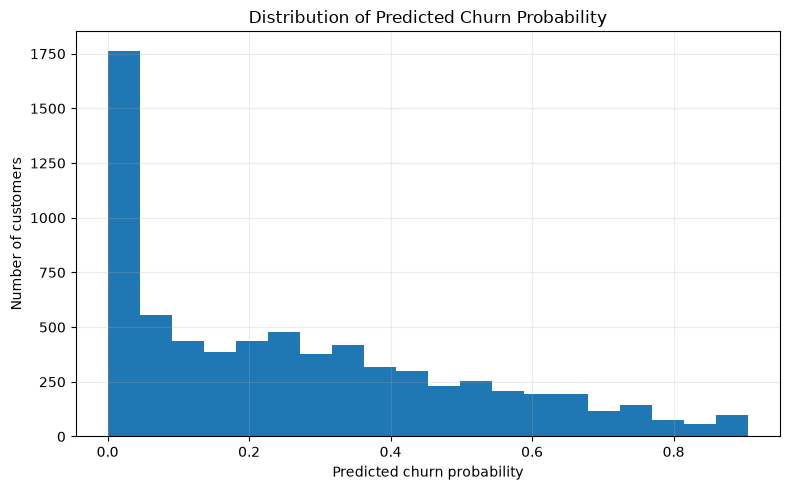

Saved: C:\CHURNIQ\REPORTS\retention\churn_risk_distribution.png


In [19]:
plt.figure(figsize=(8, 5))
plt.hist(scores["predicted_churn_probability"].dropna(), bins=20)
plt.title("Distribution of Predicted Churn Probability")
plt.xlabel("Predicted churn probability")
plt.ylabel("Number of customers")
plt.grid(alpha=0.25)
plt.tight_layout()

plot_path = OUTPUT_DIR / "churn_risk_distribution.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", plot_path.resolve())

### Export results for Notebooks 08–10

In [20]:
scores_path = OUTPUT_DIR / "customer_retention_priority.csv"
summary_path = OUTPUT_DIR / "retention_strategy_summary.json"
risk_summary_path = OUTPUT_DIR / "retention_risk_summary.csv"

scores.to_csv(scores_path, index=False)
risk_summary.to_csv(risk_summary_path, index=False)

summary = {
    "notebook": "07_customer_retention_strategy_and_prioritization",
    "source_data": str(data_path),
    "customers_scored": int(len(scores)),
    "mean_predicted_churn_probability": float(scores["predicted_churn_probability"].mean()),
    "high_risk_customers": int((scores["churn_risk_band"] == "High").sum()),
    "medium_risk_customers": int((scores["churn_risk_band"] == "Medium").sum()),
    "low_risk_customers": int((scores["churn_risk_band"] == "Low").sum()),
    "shap_context_available": bool(shap_path is not None),
    "survival_context_available": bool(km_path is not None),
    "causal_uplift_estimated": False,
    "interpretation": (
        "Risk-based retention prioritization from the existing Telco dataset. "
        "Predicted churn risk is not the same as treatment uplift."
    ),
    "outputs": {
        "customer_scores": str(scores_path),
        "risk_summary": str(risk_summary_path),
        "risk_distribution_plot": str(plot_path)
    }
}

summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Saved customer table:", scores_path.resolve())
print("Saved risk summary:", risk_summary_path.resolve())
print("Saved JSON summary:", summary_path.resolve())
print(json.dumps(summary, indent=2))

Saved customer table: C:\CHURNIQ\REPORTS\retention\customer_retention_priority.csv
Saved risk summary: C:\CHURNIQ\REPORTS\retention\retention_risk_summary.csv
Saved JSON summary: C:\CHURNIQ\REPORTS\retention\retention_strategy_summary.json
{
  "notebook": "07_customer_retention_strategy_and_prioritization",
  "source_data": "C:\\CHURNIQ\\DATA\\WA_Fn-UseC_-Telco-Customer-Churn.csv",
  "customers_scored": 7043,
  "mean_predicted_churn_probability": 0.26580147145039634,
  "high_risk_customers": 833,
  "medium_risk_customers": 1910,
  "low_risk_customers": 4300,
  "shap_context_available": true,
  "survival_context_available": true,
  "causal_uplift_estimated": false,
  "interpretation": "Risk-based retention prioritization from the existing Telco dataset. Predicted churn risk is not the same as treatment uplift.",
  "outputs": {
    "customer_scores": "C:\\CHURNIQ\\reports\\retention\\customer_retention_priority.csv",
    "risk_summary": "C:\\CHURNIQ\\reports\\retention\\retention_risk_su